In [1]:
import numpy as np
import basilisk_runner
import importlib
import dynamics
import utils
import matplotlib.pyplot as plt

/Users/shash/Documents/Projects/SatelliteRendezvous/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
importlib.reload(basilisk_runner)
importlib.reload(dynamics)
importlib.reload(utils)

<module 'utils' from '/Users/shash/Documents/Projects/SatelliteRendezvous/utils.py'>

In [3]:
from basilisk_runner import run_orbit
from Basilisk.utilities import orbitalMotion, simIncludeGravBody


In [4]:
history = run_orbit(duration_s=60.0, dt_s = 0.1)


time_s_chief = history["time_s_chief"]
position_m_chief = history["position_m_chief"]
velocity_mps_chief = history["velocity_mps_chief"]
radius_m_chief = np.linalg.norm(position_m_chief, axis=1)

time_s_chaser = history["time_s_chaser"]
position_m_chaser = history["position_m_chaser"]
velocity_mps_chaser = history["velocity_mps_chaser"]
radius_m_chaser = np.linalg.norm(position_m_chaser, axis=1)

In [5]:
print(f"Samples: {len(time_s_chief)}")
print(f"Initial position Chief: {position_m_chief[0]}")
print(f"Final position Chief:   {position_m_chief[-1]}")
print(f"Initial radius Chief:   {radius_m_chief[0]:,.3f} m")
print(f"Final radius Chief:     {radius_m_chief[-1]:,.3f} m")


Samples: 601
Initial position Chief: [6777000.       0.       0.]
Final position Chief:   [6761361.56919877  459798.07979944       0.        ]
Initial radius Chief:   6,777,000.000 m
Final radius Chief:     6,776,977.537 m


In [6]:
print(f"Initial position Chaser: {position_m_chaser[0]}")
print(f"Final position Chaser:   {position_m_chaser[-1]}")
print(f"Initial radius Chaser:   {radius_m_chaser[0]:,.3f} m")
print(f"Final radius Chaser:     {radius_m_chaser[-1]:,.3f} m")

Initial position Chaser: [6777010.       0.       0.]
Final position Chaser:   [ 6.76137162e+06  4.59797739e+05 -5.36562982e-16]
Initial radius Chaser:   6,777,010.000 m
Final radius Chaser:     6,776,987.537 m


In [7]:
from Basilisk.utilities import orbitalMotion

result = run_orbit(duration_s=60.0)
np.testing.assert_array_equal(result["time_s_chief"], result["time_s_chaser"])

for i in (0, -1):
    position_hill, _ = orbitalMotion.rv2hill(
        result["position_m_chief"][i],
        result["velocity_mps_chief"][i],
        result["position_m_chaser"][i],
        result["velocity_mps_chaser"][i],
    )
    x, y, z = np.asarray(position_hill).reshape(3)
    t = result["time_s_chief"][i]
    print(f"t={t:.1f} s | radial={x:.3f} m | along-track={y:.3f} m | cross-track={z:.3f} m")

t=0.0 s | radial=10.000 m | along-track=0.000 m | cross-track=0.000 m
t=60.0 s | radial=10.000 m | along-track=-1.022 m | cross-track=-0.000 m


In [8]:
def simulate_CW(state0, a, mu, dt, T):
    num_steps = int(T / dt)
    time_history = np.arange(num_steps + 1) * dt
    state_history = np.empty((num_steps + 1, 6), dtype=float)
    state_history[0] = np.asarray(state0, dtype=float).reshape(6)

    n = dynamics.orbital_rate(a, mu)
    A, B = dynamics.cw_matrices(n)
    control = np.zeros(3) 

    for i in range(num_steps):
        state_history[i + 1] = utils.rk4(
            dynamics.cw_derivative, state_history[i], dt, A, B, control
        )

    return time_history, state_history

In [9]:
# Simulation Constants

dt = 0.1
T = 60.0
a = 6_777_000.0
chaser_radius = a + 30.0


gravity = simIncludeGravBody.gravBodyFactory()
mu = gravity.createEarth().mu

# Run both the basilisk orbital simulation as well as the open-loop Colhessy-Wiltshire simulation

result = run_orbit(
    radius_m_chief=a,
    radius_m_chaser=chaser_radius,
    dt_s=dt,
    duration_s=T,
)

np.testing.assert_allclose(
    result["time_s_chief"], result["time_s_chaser"], rtol=0, atol=1e-9
)
basilisk_time = result["time_s_chief"] - result["time_s_chief"][0]

basilisk_hill = np.empty((len(basilisk_time), 6))
for i in range(len(basilisk_time)):
    position, velocity = orbitalMotion.rv2hill(
        result["position_m_chief"][i],
        result["velocity_mps_chief"][i],
        result["position_m_chaser"][i],
        result["velocity_mps_chaser"][i],
    )
    basilisk_hill[i, :3] = np.asarray(position).reshape(3)
    basilisk_hill[i, 3:] = np.asarray(velocity).reshape(3)

# simulate_CW calls utils.rk4 with dynamics.cw_derivative.
cw_time, cw_state = simulate_CW(basilisk_hill[0], a, mu, dt, T)
np.testing.assert_allclose(cw_time, basilisk_time, rtol=0, atol=1e-9)

position_error_m = np.linalg.norm(
    basilisk_hill[:, :3] - cw_state[:, :3], axis=1
)
max_error_m = position_error_m.max()

print(f"Samples  {len(cw_time)}")
print(f"Basilisk final Hill position [m]  {basilisk_hill[-1, :3]}")
print(f"CW final Hill position [m]        {cw_state[-1, :3]}")
print(f"Maximum position difference      {max_error_m * 1000:.4f} mm")

# assert max_error_m < 1e-3, f"CW position residual exceeded 1 mm: {max_error_m:.6g} m"
print("60-second CW test passed.")

Samples  601
Basilisk final Hill position [m]  [ 3.00002540e+01 -3.05863151e+00  1.66516829e-15]
CW final Hill position [m]        [30.00000023 -3.05545535  0.        ]
Maximum position difference      3.1863 mm
60-second CW test passed.


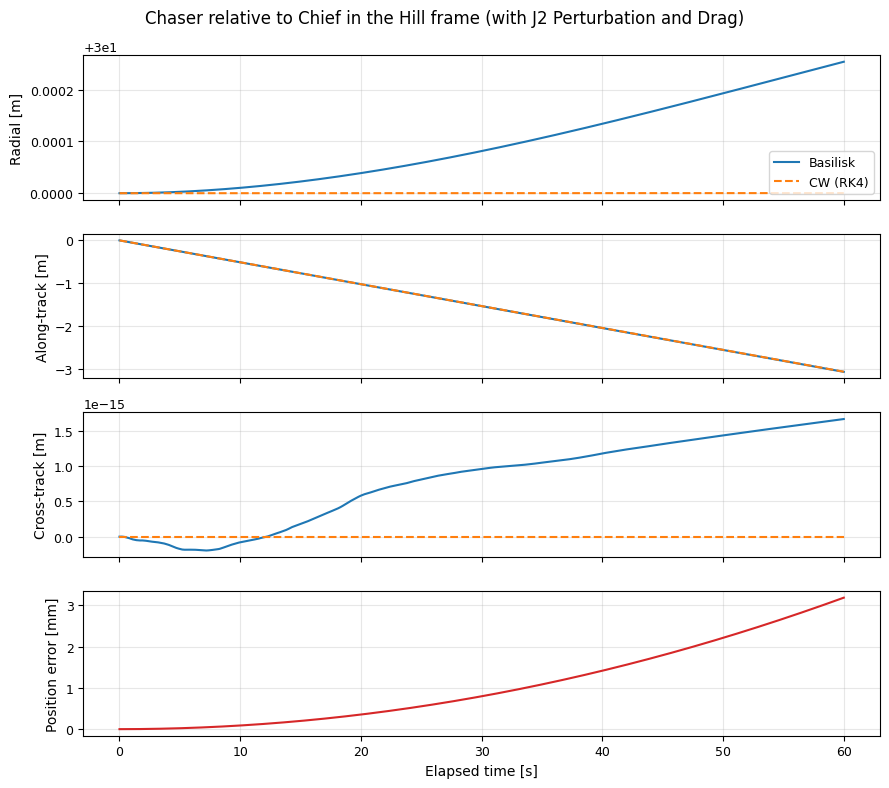

In [10]:
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(9, 8))

components = ("Radial", "Along-track", "Cross-track")
for i, (ax, component) in enumerate(zip(axes, components)):
    ax.plot(basilisk_time, basilisk_hill[:, i], label="Basilisk")
    ax.plot(cw_time, cw_state[:, i], "--", label="CW (RK4)")
    ax.set_ylabel(f"{component} [m]")
    ax.grid(alpha=0.3)

axes[0].legend()

axes[3].plot(basilisk_time, position_error_m * 1_000, color="tab:red")
axes[3].set_ylabel("Position error [mm]")
axes[3].set_xlabel("Elapsed time [s]")
axes[3].grid(alpha=0.3)

fig.suptitle("Chaser relative to Chief in the Hill frame (with J2 Perturbation and Drag)")
fig.tight_layout()
plt.show()